# A Caustics source on a second GPU

Use native Caustics construction and calls to compare the full image and all 21 ordinary derivatives before and after source-region placement. The notebook requires two physical CUDA devices and reports a skip when they are absent. Runtime and MCMC convergence are outside this comparison.
Run this notebook from the project root, or [download the example helpers](../_static/niagara-example-helpers.zip) and extract them beside a downloaded notebook. The helpers are examples, not part of the Niagara wheel.


In [1]:
import caskade
import torch

import niagara as ng

print(
    {
        "niagara": ng.__version__,
        "caskade": caskade.__version__,
        "torch": torch.__version__,
    }
)
print("CUDA device count:", torch.cuda.device_count())

{'niagara': '0.7.0', 'caskade': '1.1.5', 'torch': '2.12.0+cu126'}
CUDA device count: 2


In [2]:
if torch.cuda.device_count() < 2:
    print("SKIPPED: this example requires two physical CUDA devices.")
else:
    import caustics

    from examples.niagara_examples.caustics import image_problem

    print("Caustics version:", caustics.__version__)
    problem = image_problem(64, device="cuda:0")
    sim, params = problem.model, problem.truth
    assert isinstance(sim, caustics.LensSource)
    native_class = type(sim)
    q = params.detach().requires_grad_()
    expected = sim(q)
    expected_gradient = torch.autograd.grad(expected.square().sum(), q)[0]
    reference = expected.detach()

    with ng.enable(sim, default="cuda:0", modules={"source": "cuda:1"}, example=params) as engine:
        image = sim(params)
        assert image.device == torch.device("cuda:0")
        assert sim.source.Re.device == torch.device("cuda:1")
        torch.testing.assert_close(image, reference, atol=1e-10, rtol=1e-9)
        q = params.detach().requires_grad_()
        gradient = torch.autograd.grad(sim(q).square().sum(), q)[0]
        assert gradient.device == torch.device("cuda:0")
        torch.testing.assert_close(gradient, expected_gradient, atol=1e-9, rtol=1e-8)
        with engine.session():
            torch.testing.assert_close(sim(params), reference)
        print("Prepared backends:", [program.backend for program in engine.programs])
        print("Source home:", sim.source.Re.device, "output home:", image.device)
        print("All gradient components:", gradient.numel())
        print(
            "Maximum gradient absolute difference:",
            (gradient - expected_gradient).abs().max().item(),
        )

    assert type(sim) is native_class
    assert sim.source.Re.device == torch.device("cuda:0")
    torch.testing.assert_close(sim(params), reference)
    print("Native dispatch and co-location restored.")

Caustics version: 1.7.1


Prepared backends: ['cuda_graph', 'inductor']
Source home: cuda:1 output home: cuda:0
All gradient components: 21
Maximum gradient absolute difference: 2.842170943040401e-14
Native dispatch and co-location restored.


## Lensed images

Both paths evaluate the same Caustics model. The first two panels share an intensity scale; the residual is split minus native.

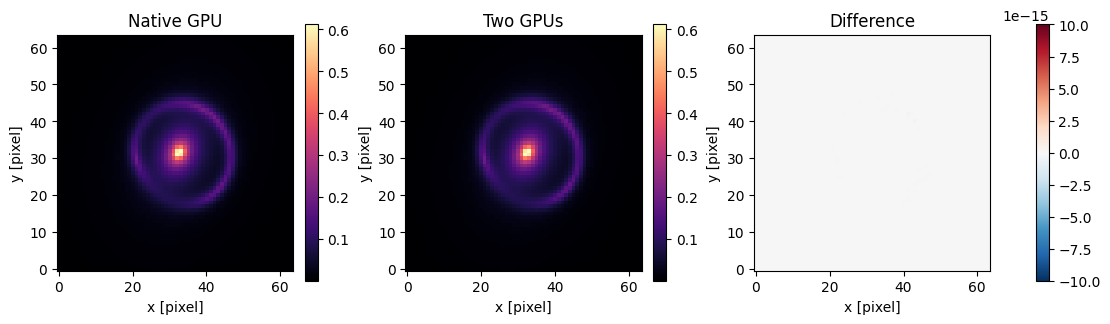

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

if torch.cuda.device_count() >= 2:
    native = reference.detach().cpu().numpy()
    split = image.detach().cpu().numpy()
    residual = split - native
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), constrained_layout=True)
    for ax, values, title in zip(axes[:2], [native, split], ["Native GPU", "Two GPUs"]):
        artist = ax.imshow(
            values, origin="lower", cmap="magma", vmin=native.min(), vmax=native.max()
        )
        ax.set(title=title, xlabel="x [pixel]", ylabel="y [pixel]")
        fig.colorbar(artist, ax=ax, shrink=0.8)
    bound = max(float(abs(residual).max()), 1e-14)
    artist = axes[2].imshow(residual, origin="lower", cmap="RdBu_r", vmin=-bound, vmax=bound)
    axes[2].set(title="Difference", xlabel="x [pixel]", ylabel="y [pixel]")
    fig.colorbar(artist, ax=axes[2], shrink=0.8)
    plt.show()